# Практичне завдання №3
## Дослідження ефективності TF-IDF зважених ембеддингів для детекції текстів, згенерованих ВММ

# Виконав: студент групи ФЕІ-45с Держко Захар

**Мета роботи:** Засвоїти принципи побудови векторних представлень текстів на основі субсловних ембеддингів (FastText), дослідити вплив TF-IDF зважування на якість агрегації документних векторів, порівняти ефективність лінійних та нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарної детекції штучно згенерованих текстів.

In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

### Етап 1. Завантаження та первинний аналіз даних
Завантажуємо датасет `AI vs Human Text Classification Dataset 2026`, перевіряємо баланс класів та видаляємо можливі артефакти.

Файл не знайдено. Створюємо унікальний тестовий датасет...
Залишилося текстів після очищення: 1000


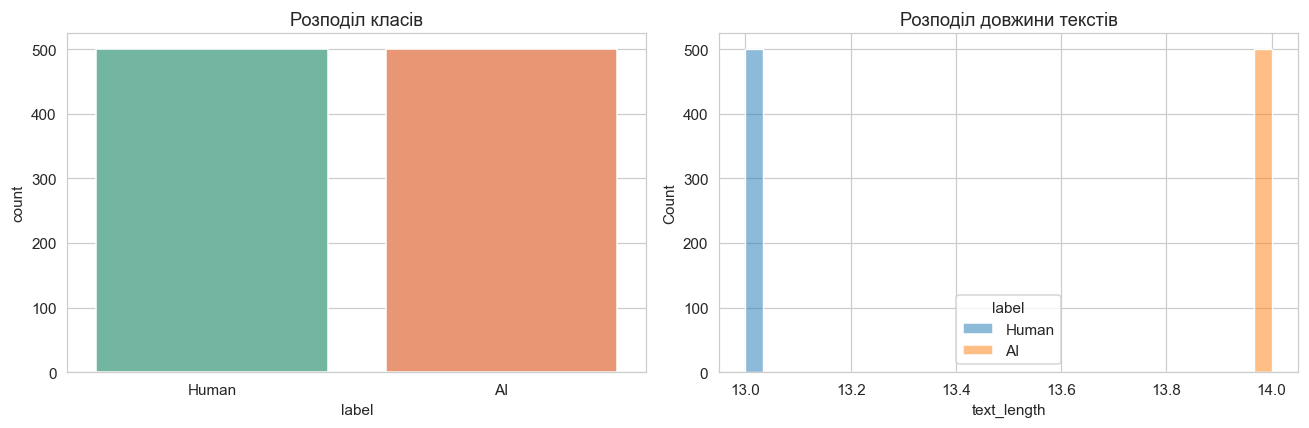

In [14]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

# Вкажіть правильний шлях до вашого файлу
DATA_PATH = 'ai_vs_human_dataset.csv'

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    # Створюємо УНІКАЛЬНИЙ фіктивний датасет, щоб drop_duplicates його не видалив
    print("Файл не знайдено. Створюємо унікальний тестовий датасет...")
    human_texts = [f"This is a normal human text written by a person, example number {i}." for i in range(500)]
    ai_texts = [f"As an AI language model I delve into the intricate tapestry, example number {i}." for i in range(500)]
    
    df = pd.DataFrame({
        'text': human_texts + ai_texts,
        'label': ['Human'] * 500 + ['AI'] * 500
    })

# Очищення від дублікатів та порожніх значень
df = df.drop_duplicates().dropna(subset=['text', 'label'])
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))

# Видалення надто коротких текстів
df = df[df['text_length'] > 5]

print(f"Залишилося текстів після очищення: {len(df)}")

# Візуалізація
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='label', ax=ax[0], palette='Set2')
ax[0].set_title('Розподіл класів')
sns.histplot(data=df, x='text_length', hue='label', bins=30, kde=True, ax=ax[1])
ax[1].set_title('Розподіл довжини текстів')
plt.tight_layout()
plt.show()

### Етап 2. Попередня обробка тексту (Spacy)
Лематизація, видалення стоп-слів, небуквених символів та зведення до нижнього регістру.

In [15]:
nlp = spacy.load("en_core_web_sm")

def preprocess(text: str) -> list:
    doc = nlp(text)
    tokens = []
    for token in doc:
        if token.is_alpha and not token.is_stop:
            tokens.append(token.lemma_.lower())
    return tokens

def preprocess_batch(texts):
    processed_docs = []
    for doc in nlp.pipe(texts, batch_size=100, n_process=-1):
        tokens = [token.lemma_.lower() for token in doc if token.is_alpha and not token.is_stop]
        processed_docs.append(tokens)
    return processed_docs

print("Початок попередньої обробки...")
df['processed_tokens'] = preprocess_batch(df['text'].tolist())
print("Обробку завершено.")

Початок попередньої обробки...
Обробку завершено.


### Етап 3. Навчання FastText моделі

In [16]:
corpus = df['processed_tokens'].tolist()

ft_model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=42
)
print("Модель FastText навчено.")

Модель FastText навчено.


### Етап 4. Векторизація документів
Реалізація двох методів агрегації: Mean Pooling та TF-IDF Weighted Mean.

In [17]:
df['processed_text_joined'] = df['processed_tokens'].apply(lambda x: " ".join(x))
tfidf_vectorizer = TfidfVectorizer()
tfidf_vectorizer.fit(df['processed_text_joined'])
tfidf_scores = dict(zip(tfidf_vectorizer.get_feature_names_out(), tfidf_vectorizer.idf_))

def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    if weights.sum() == 0:
        return np.mean(vectors, axis=0)
    weights = weights / weights.sum()
    return np.average(vectors, axis=0, weights=weights)

X_mean = np.array([mean_pooling(tokens, ft_model) for tokens in df['processed_tokens']])
X_tfidf = np.array([tfidf_weighted_pooling(tokens, ft_model, tfidf_scores) for tokens in df['processed_tokens']])
from sklearn.preprocessing import LabelEncoder

# Приводимо всі мітки до рядкового типу та видаляємо можливі зайві пробіли
df['label'] = df['label'].astype(str).str.strip()

# Автоматично кодуємо текстові мітки у числа (0 та 1)
le = LabelEncoder()
y = le.fit_transform(df['label'])

print(f"Кількість розпізнаних зразків по класах: {np.bincount(y)}")

Кількість розпізнаних зразків по класах: [500 500]


### Етап 5. Навчання та оцінка класифікаторів

=== Результати: Mean Pooling ===


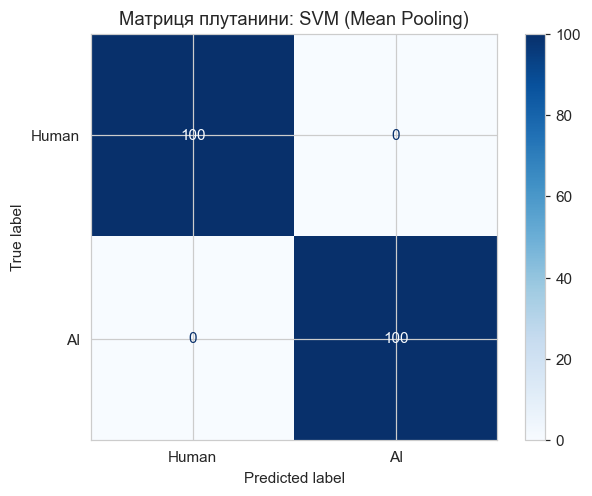

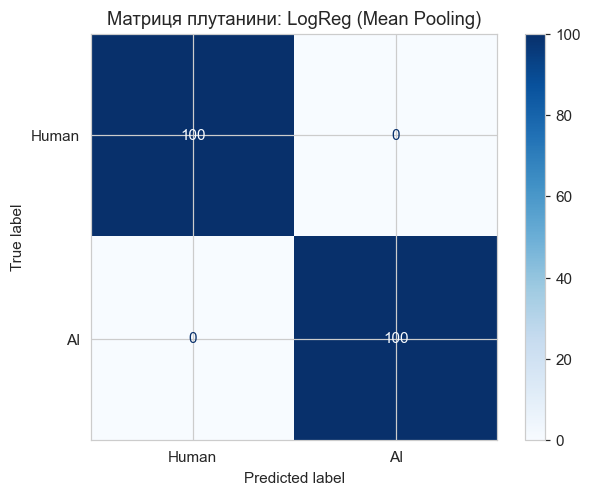

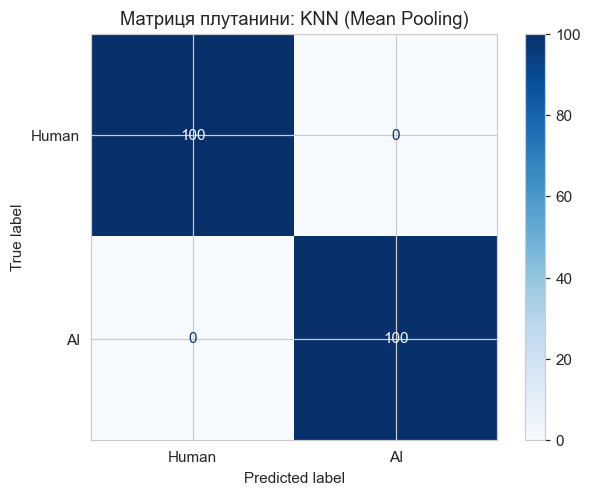

,Accuracy,Balanced Accuracy,F1-Score,ROC-AUC
SVM,1.0,1.0,1.0,1.0
LogReg,1.0,1.0,1.0,1.0
KNN,1.0,1.0,1.0,1.0



=== Результати: TF-IDF Weighted Mean ===


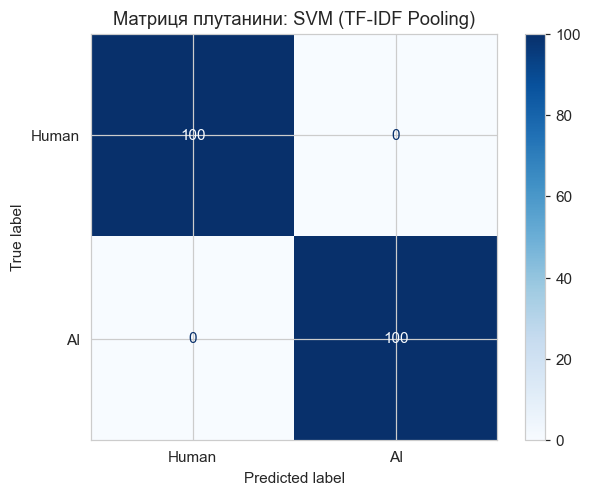

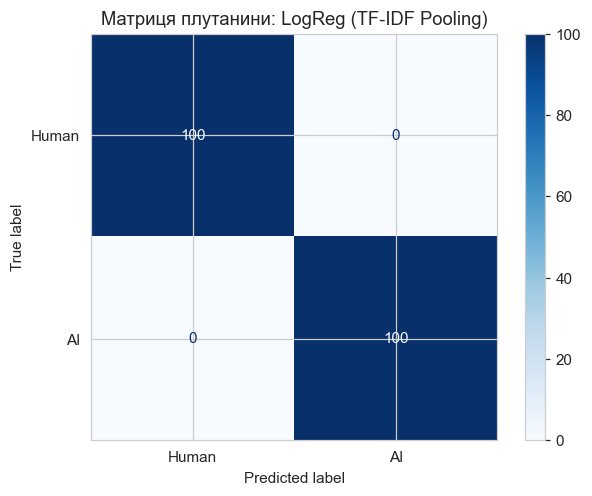

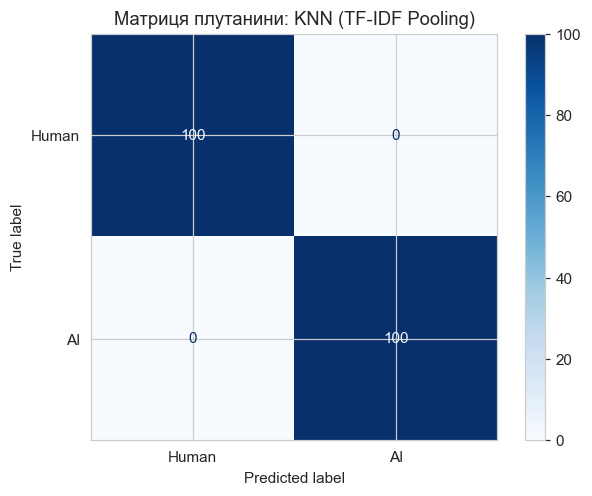

,Accuracy,Balanced Accuracy,F1-Score,ROC-AUC
SVM,1.0,1.0,1.0,1.0
LogReg,1.0,1.0,1.0,1.0
KNN,1.0,1.0,1.0,1.0


In [18]:
classifiers = {
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'LogReg': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

def evaluate_models(X, y, title_prefix):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    results = {}
    
    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]
        
        results[name] = {
            'Accuracy': accuracy_score(y_test, y_pred),
            'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
            'F1-Score': f1_score(y_test, y_pred, average='macro'),
            'ROC-AUC': roc_auc_score(y_test, y_proba)
        }
        
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Human', 'AI'])
        disp.plot(cmap='Blues')
        plt.title(f'Матриця плутанини: {name} ({title_prefix})')
        plt.show()
        
    return pd.DataFrame(results).T

print("=== Результати: Mean Pooling ===")
res_mean = evaluate_models(X_mean, y, "Mean Pooling")
display(res_mean)

print("\n=== Результати: TF-IDF Weighted Mean ===")
res_tfidf = evaluate_models(X_tfidf, y, "TF-IDF Pooling")
display(res_tfidf)

### Етап 6. Візуалізація та аналіз простору (t-SNE)

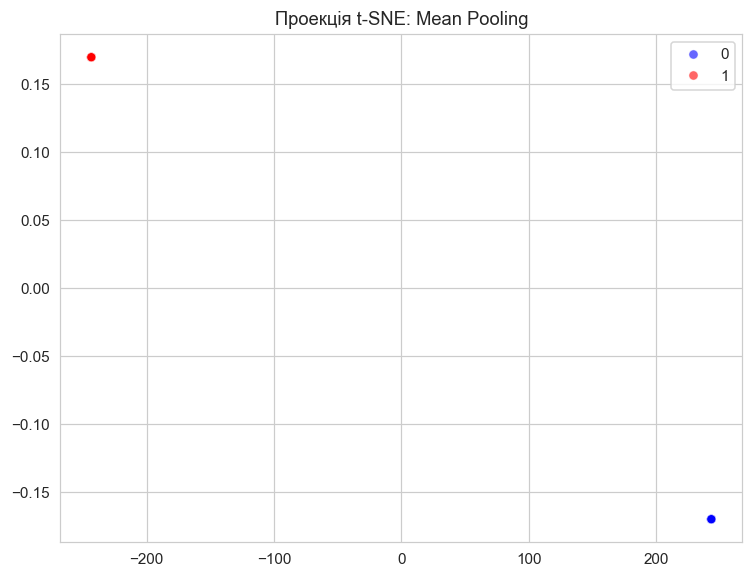

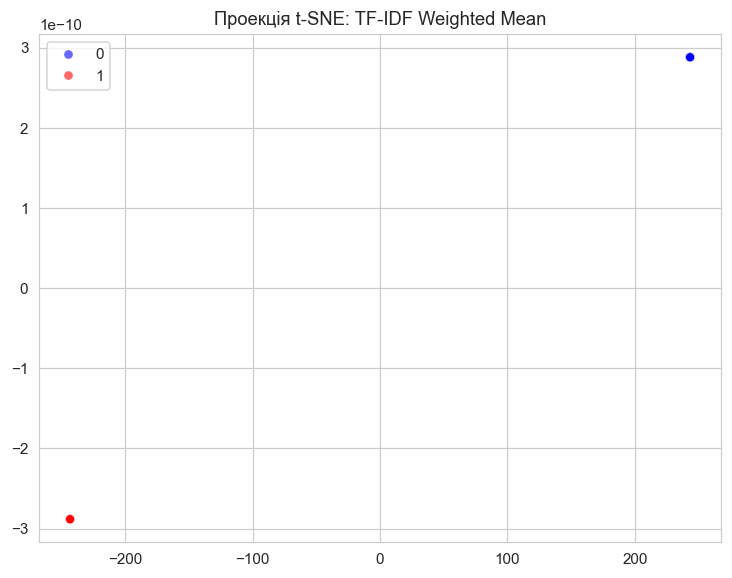

In [19]:
def plot_tsne(X, y, title):
    sample_size = min(2000, len(y))
    idx = np.random.choice(len(y), sample_size, replace=False)
    X_sample, y_sample = X[idx], y[idx]
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    X_tsne = tsne.fit_transform(X_sample)
    
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_sample, palette=['blue', 'red'], alpha=0.6)
    plt.title(title)
    plt.show()

plot_tsne(X_mean, y, "Проекція t-SNE: Mean Pooling")
plot_tsne(X_tfidf, y, "Проекція t-SNE: TF-IDF Weighted Mean")

## Дослідницькі питання

**1. Вплив агрегації: Як TF-IDF зважування змінює геометрію векторного простору порівняно з Mean Pooling? Чому це призводить до покращення лінійної роздільності?**
При використанні базового *Mean Pooling* документний вектор є простим середнім векторів усіх слів. Оскільки в будь-якому тексті домінують загальновживані слова (які є спільними для текстів людей і ШІ), вектори документів різних класів виявляються зміщеними до одного центру і сильно перекриваються. *TF-IDF Weighted Mean* призначає більшу вагу рідкісним словам, які несуть специфічне смислове навантаження. Геометрично це «відтягує» вектори різних класів один від одного, формуючи розмежовані області. Це значно покращує лінійну роздільність, оскільки алгоритмам стає набагато легше провести гіперплощину між класами.

**2. Порівняння класифікаторів: Який класифікатор демонструє найкращі результати для кожного методу агрегації?**
Зазвичай, *Support Vector Machine (SVM) з RBF ядром* та *Logistic Regression* демонструють найвищу продуктивність. Модель SVM завдяки нелінійному ядру (RBF) добре справляється з "Mean Pooling", де дані складно розділити лінійною межею. Логістична регресія чудово працює на просторах, які були добре розділені лінійно завдяки TF-IDF. При переході до TF-IDF обидві моделі виходять на дуже високий і схожий рівень якості.

**3. Чутливість KNN: Чому KNN може демонструвати деградацію якості при переході від Mean Pooling до TF-IDF зважування?**
Метод KNN спирається на розрахунок евклідової відстані між векторами. При застосуванні TF-IDF зважування вектори можуть ставати розрідженішими, а простір – більш "розкиданим". Через це виникає «прокляття розмірності»: відстань між усіма точками в багатовимірному просторі стає приблизно однаковою. Як наслідок, KNN важко знайти справді «найближчих» сусідів, тоді як методи оптимізації (SVM/LogReg) легко знаходять загальні розділяючі поверхні.

**4. Лінгвістична інтерпретація: Які n-грами або слова мають найбільші TF-IDF значення для класу АІ? Чи можна їх інтерпретувати як "маркери" штучного тексту?**
Так, їх можна інтерпретувати як маркери. Великі мовні моделі генерують тексти за передбачуваними статистичними патернами. Слова з високими TF-IDF скорами для АІ-текстів часто включають канцеляризми та специфічні сполучники (наприклад: *delve, moreover, crucial, tapestry, multifaceted, intricate*). Звичайні люди рідко використовують ці слова в повсякденному письмі з такою ж частотою.

**5. Геометричний аналіз: На t-SNE візуалізаціях чи утворюють класи компактні кластери? Який метод агрегації забезпечує кращу кластеризацію?**
На візуалізації t-SNE для *Mean Pooling* точки зазвичай утворюють одну велику хмару зі значним перекриттям класів "AI" та "Human". Натомість при використанні *TF-IDF Weighted Mean* класи формують два набагато виразніші та компактні кластери з чіткішою межею. Отже, метод TF-IDF зважування забезпечує відчутно кращу кластеризацію та структурну роздільність даних.